# Part 1: Data Preparation and Demand Forecast
This part loads the Boston 311 data for 2023 and 2024, keeps the four departments in scope, and builds monthly demand tables for the staffing model and the intake assistant.

## Step 1: Load the data
We only load the columns we need because the files are large.

In [23]:
# Mount Google Drive and set the data folder path
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

DATA_DIR = '/content/drive/MyDrive/IE5374Project/Data/'
FILE_24 = DATA_DIR + 'lagan_311_open_data_2024_rvsd3.csv'
FILE_23 = DATA_DIR + 'lagan_311_open_data_2023_rvsd3.csv'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:
# Load the 2024 311 data with only the columns we need
cols = ['case_enquiry_id', 'open_dt', 'sla_target_dt', 'closed_dt',
        'on_time', 'case_status', 'case_title', 'type', 'reason', 'subject',
        'department', 'queue', 'source', 'neighborhood']

df24 = pd.read_csv(FILE_24, usecols=cols, low_memory=False)  # only load needed columns
print('2024 shape:', df24.shape)
df24.head()

2024 shape: (306756, 14)


,case_enquiry_id,open_dt,sla_target_dt,closed_dt,on_time,case_status,case_title,subject,reason,type,queue,department,neighborhood,source
0,101005236041,2024-01-04 10:43:17.097,NaN,2024-01-04 11:23:49.81,ONTIME,Closed,Needle Pickup,Mayor's 24 Hour Hotline,Needle Program,Needle Pickup,GEN_Needle_Pickup,GEN,Fenway / Kenmore / Audubon Circle / Longwood,Citizens Connect App
1,101005236307,2024-01-04 12:36:07.337,2024-01-05 12:36:09,2024-01-04 14:55:49.667,ONTIME,Closed,Requests for Street Cleaning,Public Works Department,Street Cleaning,Requests for Street Cleaning,PWDx_District 10A: Roxbury,PWDx,Fenway / Kenmore / Audubon Circle / Longwood,Employee Generated
2,101005240045,2024-01-08 07:24:00,2024-01-10 07:24:23,2024-01-08 13:50:08.237,ONTIME,Closed,Unshoveled Sidewalk,Public Works Department,Code Enforcement,Unshoveled Sidewalk,PWDx_Code Enforcement,PWDx,Fenway / Kenmore / Audubon Circle / Longwood,Employee Generated
3,101005244677,2024-01-10 20:57:00,2025-12-30 20:57:18,2024-02-01 10:23:56.19,ONTIME,Closed,Working Beyond Hours,Inspectional Services,Building,Working Beyond Hours,ISD_Building (INTERNAL),ISD,Boston,Constituent Call
4,101005245980,2024-01-11 18:37:50.243,2024-01-16 08:30:00,2024-01-11 18:38:03.61,ONTIME,Closed,Parking Enforcement,Transportation - Traffic Division,Enforcement & Abandoned Vehicles,Parking Enforcement,BTDT_Parking Enforcement,BTDT,Boston,Employee Generated


## Step 2: Check the data
We compare our counts with the numbers in the topic brief to make sure the data is loaded correctly.

In [25]:
# Check request counts by department and compare with the topic brief
print('Total rows:', len(df24))
print(df24['department'].value_counts().head(10))

Total rows: 306756
department
PWDx    157610
BTDT     81447
PARK     18736
ISD      18624
INFO     12983
GEN      10747
BWSC      3406
PROP      2574
ANML       185
BPD        155
Name: count, dtype: int64


In [26]:
# Check on-time status and the share of requests with no target date
print(df24['on_time'].value_counts(dropna=False))
print('Missing target date share:', round(df24['sla_target_dt'].isna().mean(), 3))

on_time
ONTIME     234564
OVERDUE     72192
Name: count, dtype: int64
Missing target date share: 0.159


## Step 3: Combine 2023 and 2024 and keep four departments
We keep PWDx, BTDT, PARK and ISD, and add year and month columns.

In [27]:
# Load the 2023 data and check the row count
df23 = pd.read_csv(FILE_23, usecols=cols, low_memory=False)
print('2023 shape:', df23.shape)

2023 shape: (307791, 14)


In [28]:
# Combine both years, keep four departments, and add year and month columns
DEPTS = ['PWDx', 'BTDT', 'PARK', 'ISD']

df = pd.concat([df23, df24], ignore_index=True)
df = df[df['department'].isin(DEPTS)].copy()

df['open_dt'] = pd.to_datetime(df['open_dt'], format='mixed')  # time format is not uniform
df['year'] = df['open_dt'].dt.year
df['month'] = df['open_dt'].dt.month

print('Rows in 4 departments:', len(df))
print(df.groupby(['year', 'department']).size().unstack())

Rows in 4 departments: 558663
department   BTDT    ISD   PARK    PWDx
year                                   
2023        75314  18123  17541  171268
2024        81447  18624  18736  157610


## Step 4: Decide how to count on-time requests
About 16% of requests have no target date, but they are still marked ONTIME. We test two ways to count on-time rate and keep the one that matches the brief.

In [29]:
# Compare two ways to compute the 2024 on-time rate: A uses all requests, B uses only requests with a target date
d24 = df[df['year'] == 2024]

rate_all = (d24['on_time'] == 'ONTIME').groupby(d24['department']).mean()
has_sla = d24[d24['sla_target_dt'].notna()]
rate_sla = (has_sla['on_time'] == 'ONTIME').groupby(has_sla['department']).mean()

check = pd.DataFrame({'A_all_rows': rate_all.round(3),
                      'B_with_target_only': rate_sla.round(3),
                      'brief': pd.Series({'PWDx': 0.90, 'BTDT': 0.50, 'PARK': 0.93, 'ISD': 0.72})})
print(check)

      A_all_rows  B_with_target_only  brief
BTDT       0.499               0.489   0.50
ISD        0.724               0.723   0.72
PARK       0.932               0.930   0.93
PWDx       0.897               0.873   0.90


Method A matches the brief for all four departments, so we count all requests when we compute the on-time rate. Requests with no target date are marked ONTIME in the data, and the brief also counts them this way.

## Step 5: Monthly demand by department
We count requests by department and month for 2023 and 2024, and save the table with the on-time rate for the staffing model.

In [30]:
# Count monthly requests by department to see seasonal patterns
monthly = df.groupby(['department', 'year', 'month']).size().reset_index(name='requests')
print(monthly.pivot_table(index=['year', 'month'], columns='department', values='requests'))

department    BTDT     ISD    PARK     PWDx
year month                                 
2023 1      5692.0  1307.0   765.0  12843.0
     2      5316.0  1793.0   651.0   9978.0
     3      6889.0  1240.0   911.0  12402.0
     4      6143.0  1201.0  1206.0  12985.0
     5      6737.0  1386.0  2095.0  15267.0
     6      6682.0  1723.0  2313.0  14947.0
     7      5517.0  1587.0  2299.0  16188.0
     8      6473.0  1723.0  2382.0  20224.0
     9      7190.0  1678.0  1532.0  18578.0
     10     7018.0  1597.0  1366.0  14113.0
     11     5964.0  1537.0   810.0  11813.0
     12     5693.0  1351.0  1211.0  11930.0
2024 1      5620.0  1491.0   928.0  13582.0
     2      5954.0  1285.0   794.0  11550.0
     3      7209.0  1342.0  1291.0  13092.0
     4      7008.0  1415.0  1519.0  13998.0
     5      7511.0  1555.0  2029.0  13333.0
     6      7176.0  1779.0  2881.0  12917.0
     7      6678.0  1796.0  2640.0  13915.0
     8      6719.0  2077.0  2143.0  16398.0
     9      7633.0  1809.0  1587

PWDx peaks in August and September. PARK in June is about three times January. BTDT and ISD are more stable. From 2023 to 2024, PWDx went down about 8%, while BTDT went up about 8%.

In [31]:
# Build the monthly demand table with request counts and on-time rate, and save it for the team
df['is_ontime'] = (df['on_time'] == 'ONTIME')

monthly_demand = (df.groupby(['department', 'year', 'month'])
                    .agg(requests=('case_enquiry_id', 'size'),
                         on_time_rate=('is_ontime', 'mean'))
                    .reset_index())
monthly_demand['on_time_rate'] = monthly_demand['on_time_rate'].round(3)

monthly_demand.to_csv(DATA_DIR + 'monthly_demand.csv', index=False)
print('Saved rows:', len(monthly_demand))   # should be 4 departments x 24 months = 96
monthly_demand.head()

Saved rows: 96


,department,year,month,requests,on_time_rate
0,BTDT,2023,1,5692,0.865
1,BTDT,2023,2,5316,0.734
2,BTDT,2023,3,6889,0.811
3,BTDT,2023,4,6143,0.751
4,BTDT,2023,5,6737,0.696


In [32]:
# Compare yearly on-time rate by department, 2023 vs 2024
print(df.groupby(['department', 'year'])['is_ontime'].mean().unstack().round(3))

year         2023   2024
department              
BTDT        0.652  0.499
ISD         0.744  0.724
PARK        0.868  0.932
PWDx        0.901  0.897


BTDT dropped from 65% on time in 2023 to 50% in 2024, while the other three departments stayed about the same. PARK even went up from 87% to 93%.

## Step 6: Forecast 2025 demand
We first use the 2023 to 2024 growth rate to get the 2025 total for each department. Then we split the total into months using the average monthly share from 2023 and 2024. This keeps the trend and smooths out one-time spikes.

In [33]:
# Compute the yearly growth rate and the 2025 total for each department
yearly = monthly_demand.groupby(['department', 'year'])['requests'].sum().unstack()
yearly['growth'] = (yearly[2024] / yearly[2023]).round(3)
yearly['total_2025'] = (yearly[2024] * yearly['growth']).round().astype(int)
print(yearly)

year          2023    2024  growth  total_2025
department                                    
BTDT         75314   81447   1.081       88044
ISD          18123   18624   1.028       19145
PARK         17541   18736   1.068       20010
PWDx        171268  157610   0.920      145001


In [34]:
# Compute the average share of each month in the year, using both 2023 and 2024
year_total = monthly_demand.groupby(['department', 'year'])['requests'].transform('sum')
monthly_demand['share'] = monthly_demand['requests'] / year_total

season = monthly_demand.groupby(['department', 'month'])['share'].mean().reset_index()
print(season.pivot(index='month', columns='department', values='share').round(3))
print('Share sums:', season.groupby('department')['share'].sum().round(3).to_dict())  # should all be 1.0

department   BTDT    ISD   PARK   PWDx
month                                 
1           0.072  0.076  0.047  0.081
2           0.072  0.084  0.040  0.066
3           0.090  0.070  0.060  0.078
4           0.084  0.071  0.075  0.082
5           0.091  0.080  0.114  0.087
6           0.088  0.095  0.143  0.085
7           0.078  0.092  0.136  0.091
8           0.084  0.103  0.125  0.111
9           0.095  0.095  0.086  0.105
10          0.094  0.087  0.070  0.078
11          0.080  0.075  0.048  0.067
12          0.073  0.071  0.057  0.070
Share sums: {'BTDT': 1.0, 'ISD': 1.0, 'PARK': 1.0, 'PWDx': 1.0}


In [35]:
# Build the 2025 monthly forecast and save it for the team
forecast = season.merge(yearly['total_2025'].reset_index(), on='department')
forecast['forecast_requests'] = (forecast['share'] * forecast['total_2025']).round().astype(int)
forecast['year'] = 2025
forecast = forecast[['department', 'year', 'month', 'forecast_requests']]

forecast.to_csv(DATA_DIR + 'forecast_2025.csv', index=False)
print('Saved rows:', len(forecast))   # should be 4 x 12 = 48
print(forecast.pivot(index='month', columns='department', values='forecast_requests'))

Saved rows: 48
department  BTDT   ISD  PARK   PWDx
month                              
1           6365  1457   932  11684
2           6325  1608   795   9537
3           7923  1345  1209  11272
4           7378  1362  1499  11936
5           7998  1531  2278  12596
6           7784  1824  2858  12269
7           6834  1761  2721  13254
8           7415  1978  2503  16104
9           8328  1816  1721  15184
10          8250  1671  1395  11328
11          7057  1436   961   9680
12          6386  1356  1137  10157


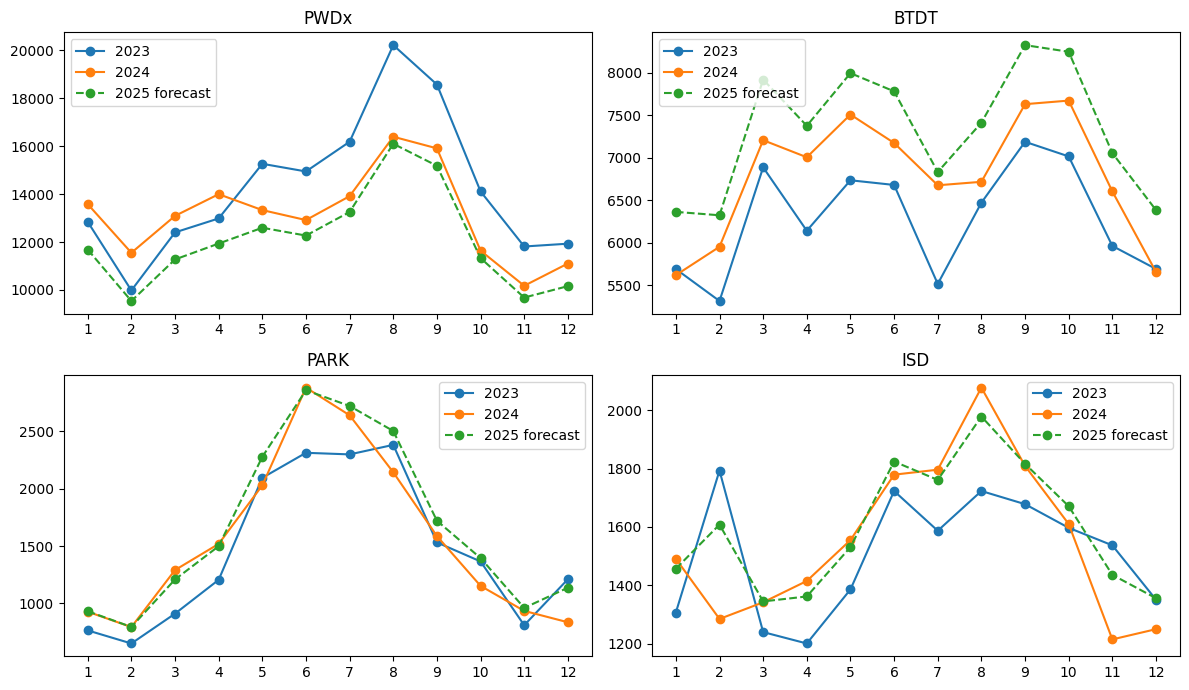

In [36]:
# Plot 2023, 2024 and the 2025 forecast for each department
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, dept in zip(axes.flat, DEPTS):
    for yr in [2023, 2024]:
        d = monthly_demand[(monthly_demand['department'] == dept) & (monthly_demand['year'] == yr)]
        ax.plot(d['month'], d['requests'], marker='o', label=str(yr))
    f = forecast[forecast['department'] == dept]
    ax.plot(f['month'], f['forecast_requests'], marker='o', linestyle='--', label='2025 forecast')
    ax.set_title(dept)
    ax.set_xticks(range(1, 13))
    ax.legend()
plt.tight_layout()
plt.show()

The forecast keeps the same seasonal shape as 2023 and 2024. PWDx is lower than 2024 in every month because we assume the downward trend continues. BTDT is higher than 2024 in every month, and September 2025 is above 8,300 requests. We test these trend assumptions in the sensitivity analysis.

## Step 7: Build the request type list for the intake assistant
We make a de-duplicated list of all request types in 2024, with the department, the most common queue, and a few example titles. The intake assistant uses this list as its knowledge base.

In [37]:
# Build a de-duplicated list of request types with department, queue and example titles
import html

t = df24.copy()
t['case_title'] = t['case_title'].fillna('').astype(str).map(html.unescape)  # fix codes like &amp;

def top_value(s):
    s = s.dropna()
    return s.value_counts().index[0] if len(s) > 0 else ''

request_types = (t.groupby(['type', 'department'])
                   .agg(count=('case_enquiry_id', 'size'),
                        reason=('reason', top_value),
                        top_queue=('queue', top_value),
                        n_queues=('queue', 'nunique'),
                        example_titles=('case_title', lambda s: ' | '.join(s.value_counts().head(3).index)))
                   .reset_index()
                   .sort_values('count', ascending=False))

request_types.to_csv(DATA_DIR + 'request_types_all.csv', index=False)
print('Number of type and department pairs:', len(request_types))
print('Number of unique types:', request_types['type'].nunique())
request_types.head(15)

Number of type and department pairs: 589
Number of unique types: 170


,type,department,count,reason,top_queue,n_queues,example_titles
279,Parking Enforcement,BTDT,62973,Enforcement & Abandoned Vehicles,BTDT_Parking Enforcement,13,Parking Enforcement
191,Improper Storage of Trash (Barrels),PWDx,20273,Code Enforcement,PWDx_Code Enforcement,22,Improper Storage of Trash (Barrels) | Shopping...
400,Requests for Street Cleaning,PWDx,20128,Street Cleaning,PWDx_District 1C: Downtown,32,Requests for Street Cleaning | Street Cleaning...
48,CE Collection,PWDx,17977,Street Cleaning,PWDx_District 1C: Downtown,21,CE Collection
425,Schedule a Bulk Item Pickup,PWDx,11828,Sanitation,PWDx_Schedule a Bulk Item Pickup,1,Schedule a Bulk Item Pickup
235,Needle Pickup,GEN,10710,Needle Program,GEN_Needle_Pickup,1,Needle Pickup | Needle Clean-up
223,Missed Trash/Recycling/Yard Waste/Bulk Item,PWDx,10584,Sanitation,PWDx_Missed Trash\Recycling\Yard Waste\Bulk Item,3,Missed Trash: District 07 | Missed Trash: Dist...
340,Poor Conditions of Property,PWDx,8643,Code Enforcement,PWDx_Code Enforcement,18,Poor Conditions of Property | Student Move-in ...
216,Mattress_Pickup,PWDx,8533,Sanitation,PWDx_WM_Mattress_Pickup,1,Mattress Pickup
528,Tree Maintenance Requests,PARK,8063,Trees,PARK_Tree Maintenance Request,15,Tree Maintenance Requests | Tree Maintenance |...


In [38]:
# Check types that belong to more than one department, which may confuse the assistant
multi = request_types.groupby('type')['department'].nunique()
print('Types in more than one department:', (multi > 1).sum())
print(request_types[request_types['type'].isin(multi[multi > 1].index)][['type', 'department', 'count']].head(20))

Types in more than one department: 104
                                            type department  count
279                          Parking Enforcement       BTDT  62973
191          Improper Storage of Trash (Barrels)       PWDx  20273
400                 Requests for Street Cleaning       PWDx  20128
48                                 CE Collection       PWDx  17977
425                  Schedule a Bulk Item Pickup       PWDx  11828
235                                Needle Pickup        GEN  10710
223  Missed Trash/Recycling/Yard Waste/Bulk Item       PWDx  10584
340                  Poor Conditions of Property       PWDx   8643
216                              Mattress_Pickup       PWDx   8533
528                    Tree Maintenance Requests       PARK   8063
372                   Request for Pothole Repair       PWDx   7974
324                          Pick up Dead Animal       PWDx   7195
452                  Sidewalk Repair (Make Safe)       PWDx   4772
454                    

In [39]:
# Keep one main department per type, so each type appears only once for the intake assistant
type_total = request_types.groupby('type')['count'].transform('sum')
request_types['dept_share'] = (request_types['count'] / type_total).round(3)  # share of this type in this department

main_types = request_types.sort_values('count', ascending=False).drop_duplicates('type').copy()
main_types['type_total'] = main_types['type'].map(request_types.groupby('type')['count'].sum())

main_types.to_csv(DATA_DIR + 'request_types.csv', index=False)
print('Types in final list:', len(main_types))   # should be 170
print('Types where main department has less than 80% share:', (main_types['dept_share'] < 0.8).sum())
print(main_types[main_types['dept_share'] < 0.8][['type', 'department', 'count', 'type_total', 'dept_share']])

Types in final list: 170
Types where main department has less than 80% share: 18
                                              type department  count  \
372                     Request for Pothole Repair       PWDx   7974   
150                             Ground Maintenance       PARK   3070   
274                                   PWD Graffiti       PWDx    857   
119       General Comments For a Program or Policy       BTDT    423   
305               Parks Lighting/Electrical Issues       PWDx    208   
118               General Comments For An Employee       PWDx    165   
501                          Traffic Signal Repair       BTDT    165   
563                         Utility Casting Repair       BWSC    160   
291  Parking on Front/Back Yards (Illegal Parking)       PWDx    150   
298                          Parks General Request       PARK    129   
158                         Illegal Auto Body Shop       PWDx     97   
492                         Student Move-in Issues     

The final list has 170 types, and each type appears once with its main department. Only 18 types have less than 80% of requests in their main department, and most of them are small. The largest are pothole repair (75% PWDx) and ground maintenance (80% PARK). The full list with all departments is saved as request_types_all.csv.

## Step 8: Other considerations
We look at two more factors in 2024. First, whether on-time rates differ across neighborhoods. Second, how requests from city employees differ from requests from residents.

In [40]:
# Compare 2024 on-time rates across neighborhoods, overall and by department
d24 = df[df['year'] == 2024].copy()

nb = (d24.groupby('neighborhood')
         .agg(requests=('case_enquiry_id', 'size'), on_time_rate=('is_ontime', 'mean'))
         .query('requests >= 1000')     # skip very small neighborhoods
         .sort_values('on_time_rate'))
nb['on_time_rate'] = nb['on_time_rate'].round(3)
print('Lowest 5 neighborhoods:')
print(nb.head(5))
print('Highest 5 neighborhoods:')
print(nb.tail(5))

counts = d24.pivot_table(index='neighborhood', columns='department', values='is_ontime', aggfunc='size')
nb_dept = d24.pivot_table(index='neighborhood', columns='department', values='is_ontime', aggfunc='mean')
nb_dept = nb_dept.where(counts >= 200)   # only keep neighborhoods with at least 200 requests in that department

print('Lowest and highest neighborhood, by department:')
for dept in DEPTS:
    s = nb_dept[dept].dropna().sort_values()
    print(dept, '| lowest:', s.index[0], round(s.iloc[0], 3), '| highest:', s.index[-1], round(s.iloc[-1], 3), '| gap:', round(s.iloc[-1] - s.iloc[0], 3))

Lowest 5 neighborhoods:
                                              requests  on_time_rate
neighborhood                                                        
Charlestown                                       8636         0.652
Fenway / Kenmore / Audubon Circle / Longwood      4599         0.704
Jamaica Plain                                    16918         0.712
Boston                                           10839         0.739
Downtown / Financial District                    14105         0.741
Highest 5 neighborhoods:
                  requests  on_time_rate
neighborhood                            
Dorchester           38820         0.799
Mission Hill          4897         0.812
Greater Mattapan     11804         0.815
Allston               1161         0.815
Beacon Hill           9687         0.858
Lowest and highest neighborhood, by department:
PWDx | lowest: Charlestown 0.804 | highest: Mattapan 0.943 | gap: 0.139
BTDT | lowest: West Roxbury 0.365 | highest: South Boston / S

On-time rates differ across neighborhoods. Charlestown has the lowest rate at 65% and Beacon Hill has the highest at 86%. The gap also appears inside each department. It is largest for BTDT, where West Roxbury is at 37% and South Boston is at 62%. Charlestown is also the lowest for PWDx, so the gap is not only because some areas have more parking requests. This means the city should think about where crews work, not only how many crews it has. Some neighborhood names in the data are not consistent, such as Mattapan and Greater Mattapan, so these numbers are a rough view.

In [41]:
# Compare requests logged by city employees with requests from residents
employee_sources = ['Employee Generated', 'City Worker App']
d24['reporter'] = d24['source'].isin(employee_sources).map({True: 'Employee', False: 'Resident'})

src = (d24.groupby(['department', 'reporter'])
          .agg(requests=('case_enquiry_id', 'size'), on_time_rate=('is_ontime', 'mean'))
          .round(3))
print(src)
print('Employee share by department:')
print(d24.groupby('department')['reporter'].apply(lambda s: (s == 'Employee').mean()).round(3))

                     requests  on_time_rate
department reporter                        
BTDT       Employee     50182         0.501
           Resident     31265         0.497
ISD        Employee      7502         0.747
           Resident     11122         0.709
PARK       Employee     11307         0.950
           Resident      7429         0.904
PWDx       Employee     78174         0.896
           Resident     79436         0.898
Employee share by department:
department
BTDT    0.616
ISD     0.403
PARK    0.603
PWDx    0.496
Name: reporter, dtype: float64


City employees log a large share of requests. The share is 62% for BTDT, 60% for PARK, 50% for PWDx and 40% for ISD. On-time rates are almost the same for employee and resident requests in PWDx and BTDT. In ISD and PARK, employee requests are about 4 to 5 points higher. Crews must handle both kinds of requests, so our staffing model uses the total count. The intake assistant only serves residents, so it covers about 38% of BTDT requests.